# Yuri behavior from the processed csv files

Loads `data/recordings/Yuri_behavior/behavior/<session>.csv`, converts it to the trial-wise dataframe and plots the target selection.

In [1]:
from popy.behavior_data_tools import load_raw_behav_csv_yuri, get_injection_yuri, get_behavior_yuri, drop_time_fields
from popy.plotting.plotting_tools import show_target_selection_compact

session = '010224'

/home/uzsombi/.config/matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /tmp/matplotlib-dvxk_n4c because there was an issue with the default path (/home/uzsombi/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
Matplotlib is building the font cache; this may take a moment.


In [2]:
# injection condition of the session ('none', 'sham', 'dcz' or 'MISSING')
injection = get_injection_yuri(session)
injection

'sham'

In [3]:
# (1) load raw events
raw_df = load_raw_behav_csv_yuri(session)
raw_df

,Event,Time
0,250,0.55107
1,8,0.04031
2,52,0.04031
3,100,0.09811
4,52,0.09811
...,...,...
11515,67,3319.73779
11516,67,3323.66469
11517,67,3327.35747
11518,67,3329.36258


In [4]:
# (2-3) convert to trial-wise dataframe, with monkey, injection and session info
joint_df = get_behavior_yuri(session)
joint_df

,monkey,injection,session,trial_id,trial_start_time,n_target_touches,lever_touch_time,lever_validation_time,lever_release_time,target_touch_time,target_validation_time,feedback_time,trial_end_time,block_id,best_target,target,feedback
0,yu,sham,010224,0,0.0981,1.0,1.9349,3.4538,4.1445,4.4818,5.0152,5.5334,6.4813,0,2,3.0,True
1,yu,sham,010224,1,6.4813,1.0,6.8342,8.3548,9.1110,9.3168,9.8476,10.3658,11.2613,0,2,3.0,False
2,yu,sham,010224,2,11.2613,1.0,20.2153,21.7303,22.7729,23.0121,23.5394,24.0590,24.9819,0,2,3.0,False
3,yu,sham,010224,3,24.9819,1.0,26.3183,27.8279,29.3000,29.5440,30.0718,30.5926,31.6706,0,2,3.0,True
4,yu,sham,010224,4,31.6706,1.0,32.0304,33.5480,34.2616,34.4816,35.0061,35.5219,36.4682,0,2,3.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
506,yu,sham,010224,506,3084.7915,1.0,3084.9430,3086.4682,3087.6332,3087.8879,3088.4070,3088.9309,3089.9700,11,2,2.0,True
507,yu,sham,010224,507,3089.9700,1.0,3090.1755,3091.6983,3092.7210,3093.0209,3093.5882,3094.2037,3097.7232,11,2,2.0,False
508,yu,sham,010224,508,3097.7232,1.0,3098.0004,3099.5132,3100.1377,3100.4441,3100.9694,3101.4934,3102.4218,11,2,2.0,False
509,yu,sham,010224,509,3102.4218,1.0,3102.5038,3104.0274,3105.9743,3106.1942,3106.7165,3107.2260,3108.2628,11,2,2.0,True


/workspace/uzsombi/inserm/PoPy/popy/plotting/plotting_tools.py:829: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()


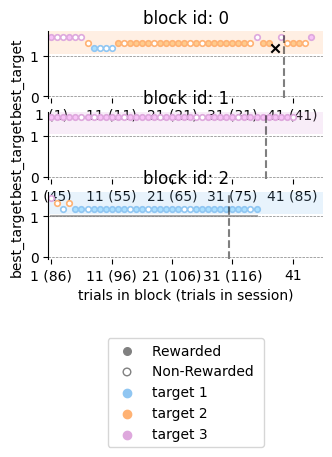

In [5]:
# (4) plot behavior
session_data = drop_time_fields(joint_df.copy())  # drop time fields (not necessary for this plotting)

show_target_selection_compact(session_data[:120],
                              format='paper',
                              background_values=['best_target'],   # here we tell what variable to use as background - value in this case
                              title=None,
                              show=True)